<a href="https://colab.research.google.com/github/rama603/Reading-Sign-Language-/blob/main/Reading_Sign_Language_stage3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Set seed for exact reproducibility across stages
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# 1. Load Data
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

X_train_full = train_df.drop(columns="label").values.astype("float32") / 255.0
y_train_full = train_df["label"].values

X_test = test_df.drop(columns="label").values.astype("float32") / 255.0
y_test = test_df["label"].values

# 2. Remap labels to contiguous range 0 to 23 (ignoring J=9 and Z=25)
unique_labels = sorted(np.unique(y_train_full))
label_map = {old_id: new_id for new_id, old_id in enumerate(unique_labels)}
inv_label_map = {new_id: old_id for new_id, old_id in enumerate(unique_labels)}

y_train_mapped = np.array([label_map[y] for y in y_train_full])
y_test_mapped = np.array([label_map[y] for y in y_test])

# 3. Maintain Exact Same Validation Split as Stages 1 & 2
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_mapped, test_size=0.2, random_state=SEED, stratify=y_train_mapped
)

# Reshape into PyTorch image tensor format: (Batch, Channels, Height, Width) -> (N, 1, 28, 28)
X_train_t = torch.tensor(X_train).view(-1, 1, 28, 28)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val).view(-1, 1, 28, 28)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_t = torch.tensor(X_test).view(-1, 1, 28, 28)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# Create DataLoaders
batch_size = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

print(f"Data prepared! Number of classes: {len(unique_labels)}")
print(f"Training batches: {len(train_loader)}, Validation batches: {len(val_loader)}")

# 4. Define the Fixed CNN Architecture Required by Project Instructions
class SignLanguageCNN(nn.Module):
    def __init__(self, num_classes=24):
        super(SignLanguageCNN, self).__init__()
        # Conv Layer 1: 1 -> 16 filters, 3x3 kernel, padding=1
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Conv Layer 2: 16 -> 32 filters, 3x3 kernel, padding=1
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Softmax classifier layer on top of extracted features
        # Image size after two 2x2 max pools: 28 -> 14 -> 7. Feature map size: 32 * 7 * 7 = 1568
        self.fc = nn.Linear(32 * 7 * 7, num_classes)

    def forward(self, x, return_features=False):
        x = self.pool1(torch.relu(self.conv1(x)))
        x = self.pool2(torch.relu(self.conv2(x)))

        # Flatten features
        features = x.view(x.size(0), -1)

        if return_features:
            return features

        out = self.fc(features)
        return out

model = SignLanguageCNN(num_classes=len(unique_labels))
print(model)

Data prepared! Number of classes: 24
Training batches: 344, Validation batches: 86
SignLanguageCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=1568, out_features=24, bias=True)
)


Using device: cpu
Starting CNN training...
Epoch [1/10] | Train Loss: 1.4188 | Train Acc: 59.92% | Val Loss: 0.4718 | Val Acc: 86.61%
Epoch [2/10] | Train Loss: 0.2490 | Train Acc: 93.62% | Val Loss: 0.1059 | Val Acc: 98.01%
Epoch [3/10] | Train Loss: 0.0676 | Train Acc: 98.96% | Val Loss: 0.0429 | Val Acc: 99.40%
Epoch [4/10] | Train Loss: 0.0223 | Train Acc: 99.90% | Val Loss: 0.0186 | Val Acc: 99.93%
Epoch [5/10] | Train Loss: 0.0108 | Train Acc: 99.98% | Val Loss: 0.0098 | Val Acc: 99.98%
Epoch [6/10] | Train Loss: 0.0077 | Train Acc: 99.96% | Val Loss: 0.0055 | Val Acc: 100.00%
Epoch [7/10] | Train Loss: 0.0034 | Train Acc: 100.00% | Val Loss: 0.0034 | Val Acc: 100.00%
Epoch [8/10] | Train Loss: 0.0022 | Train Acc: 100.00% | Val Loss: 0.0020 | Val Acc: 100.00%
Epoch [9/10] | Train Loss: 0.0015 | Train Acc: 100.00% | Val Loss: 0.0016 | Val Acc: 100.00%
Epoch [10/10] | Train Loss: 0.0013 | Train Acc: 100.00% | Val Loss: 0.0019 | Val Acc: 100.00%
Training completed in 154.49 seconds.

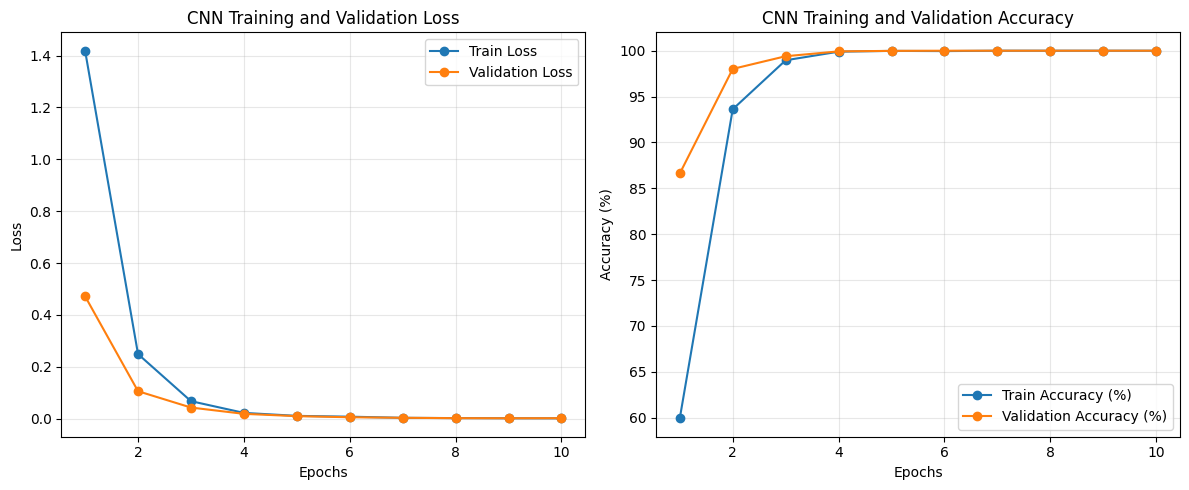

In [5]:
import torch.nn.functional as F

# 1. Hyperparameters and Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = SignLanguageCNN(num_classes=len(unique_labels)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": []
}

# 2. Training Loop with Epoch Tracking
print("Starting CNN training...")
t0 = time.time()

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train

    # Validation Evaluation
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val

    history["train_loss"].append(epoch_train_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}%")

cnn_train_time = time.time() - t0
print(f"Training completed in {cnn_train_time:.2f} seconds.")

# 3. Final Evaluation on Official Test Set

# Create test tensor using y_test_mapped instead of raw y_test
X_test_t = torch.tensor(X_test).view(-1, 1, 28, 28)
y_test_t = torch.tensor(y_test_mapped, dtype=torch.long) # <-- Using mapped labels!

test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=64, shuffle=False)
model.eval()
correct_test = 0
total_test = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total_test += labels.size(0)
        correct_test += predicted.eq(labels).sum().item()

cnn_test_acc = correct_test / total_test
print(f"\n--- STAGE 3 CNN TEST ACCURACY: {cnn_test_acc * 100:.2f}% ---")

# 4. Plot Training and Validation Curves
plt.figure(figsize=(12, 5))

# Loss Curve
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), history["train_loss"], label="Train Loss", marker='o')
plt.plot(range(1, num_epochs+1), history["val_loss"], label="Validation Loss", marker='o')
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs+1), [a*100 for a in history["train_acc"]], label="Train Accuracy (%)", marker='o')
plt.plot(range(1, num_epochs+1), [a*100 for a in history["val_acc"]], label="Validation Accuracy (%)", marker='o')
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()